# Who gains most from a coupon: an effect that changes with age

## At a glance

A retailer sent a discount coupon to some of its customers and wants to know whom to send
coupons to next time. The question is how the coupon's effect on the chance of a purchase
changes with the customer's age.

The estimated effect falls from about 27 percentage points at age 20 to under 1 point at 70, against
a true 24 and 1; up to age 60 it runs 2 to 4 points high. The rule it supports is to send coupons to
customers up to about 56, 62% of them. That rests on age, spend and visits explaining who got a
coupon, and on a method that `cleverly` labels experimental here: its theory does not cover how it
picks the curve's smoothness in this fit, and the curve has no confidence interval.

A coupon costs the profit of 0.08 purchases, so a customer's net gain is the rise in their purchase
chance minus 0.08. Learned on half the customers and scored on the other half, a rule of the same
kind (up to age 54) is estimated to earn 0.071 net purchases per customer, with a 95% interval of
0.046 to 0.096. It is the page's only measure of uncertainty for the decision.

## The question

The marketing team chose who got a coupon. It sent more coupons to customers who spent more last
year, and slightly more to older customers. Big spenders also buy more anyway. The question is,
for customers of a given age, how much a coupon raises the chance that they buy in the next
month, compared with no coupon. This is the conditional average treatment effect (CATE) given
age: the average effect among customers of that age.

A second analysis, under Go deeper, asks whether a drug's effect on the risk of an event, in a
randomized trial, changes with how severe the patient's illness is.

## Setup

Every fit sets its seed, so a rerun prints the same numbers.
The figures on this page need matplotlib: `pip install "cleverly[plot]"`.

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

import cleverly

pd.set_option("display.width", 130)
print("cleverly", cleverly.__version__)

cleverly 0.2.1


## The data

The page simulates 8,000 customers, so it knows the true effect at every age.

In [2]:
def true_uplift(age):
    """The coupon's true effect on the chance of a purchase, by age."""
    return 0.25 / (1.0 + np.exp((age - 45.0) / 8.0))


def simulate_coupons(n, seed):
    rng = np.random.default_rng(seed)
    age = rng.uniform(18, 80, n)
    spend = rng.uniform(0, 1, n)  # last year's spend, scaled to 0-1
    visits = rng.poisson(3, n).clip(0, 10)  # store visits last month
    # The team sent more coupons to big spenders, and slightly more to older customers.
    chance = 1.0 / (1.0 + np.exp(-(-1.0 + 2.5 * spend + 0.02 * (age - 50))))
    coupon = rng.binomial(1, chance)
    buys = 0.15 + 0.4 * spend + 0.02 * visits + coupon * true_uplift(age)
    bought = rng.binomial(1, buys)
    return pd.DataFrame(
        {"age": age, "spend": spend, "visits": visits, "coupon": coupon, "bought": bought}
    )


# With your own data, load the data frame here, such as frame = pd.read_csv(...), and drop
# every line that uses true_uplift: real data have no known answer.
frame = simulate_coupons(n=8_000, seed=1)
print("true effect at ages 18 and 65:", true_uplift(np.array([18, 65])).round(3))
print("rows and columns:", frame.shape)
print("column names:", list(frame.columns))
print(frame.head().round(3).to_string())

true effect at ages 18 and 65: [0.242 0.019]
rows and columns: (8000, 5)
column names: ['age', 'spend', 'visits', 'coupon', 'bought']
      age  spend  visits  coupon  bought
0  49.733  0.696       6       1       1
1  76.929  0.082       2       1       0
2  26.938  0.878       0       0       0
3  76.816  0.393       4       0       0
4  37.334  0.577       2       1       1


Each row is one customer: age, last year's spend (scaled to 0 to 1), store visits last month,
whether they got a coupon, and whether they bought in the following month. The true coupon effect
falls smoothly with age, from about 24 percentage points for the youngest customers to under 2
points after 65, and it does not depend on spend or visits.

## Why a simple comparison misleads

In [3]:
sent = frame["coupon"] == 1
print(f"share sent a coupon:          {sent.mean():.3f}")
print(
    f"mean spend, sent / not sent:  {frame.loc[sent, 'spend'].mean():.3f} / "
    f"{frame.loc[~sent, 'spend'].mean():.3f}"
)
print()
# With your own data, choose your own age bands and drop the true effect column.
bands = pd.cut(frame["age"], [18, 35, 50, 65, 80], include_lowest=True)
naive = frame.groupby([bands, "coupon"], observed=True)["bought"].mean().unstack()
table = pd.DataFrame(
    {
        "simple difference": naive[1] - naive[0],
        "true effect": frame.groupby(bands, observed=True)["age"].apply(
            lambda ages: true_uplift(ages).mean()
        ),
    }
)
print(table.round(3).to_string())

share sent a coupon:          0.556
mean spend, sent / not sent:  0.579 / 0.389

                simple difference  true effect
age                                           
(17.999, 35.0]              0.350        0.224
(35.0, 50.0]                0.207        0.143
(50.0, 65.0]                0.156        0.047
(65.0, 80.0]                0.082        0.009


Customers who got a coupon spent more last year (0.579 against 0.389), and big spenders buy more
with or without a coupon. So within each age band, the simple difference in purchase rates
overstates the effect: 0.350 against a true 0.224 for the youngest band, and 0.082 against 0.009 for
the oldest.

## State the question and what it needs

`CausalStudy` holds the data, and `design=PointTreatment(...)` says what kind of study it is:
one treatment given once (`coupon`), one outcome measured after it (`bought`), and the columns to
adjust for, which the models use to compare customers who are alike (`age`, `spend`, `visits`).
`Modifiers` names the column the effect may change with and the range of ages the curve covers.
`ConditionalContrast` is the question itself: the difference in purchase chance with and without
a coupon, as a function of age. `study.identify` returns the conditions the answer rests on and
the methods that can estimate it.

In [4]:
from cleverly import CausalStudy, ConditionalContrast, PointTreatment
from cleverly.bases import Modifiers

# For your own data, change the column names. `domains` gives the range the curve covers.
study = CausalStudy(
    frame,
    design=PointTreatment(
        outcome="bought", treatment="coupon", adjustment=("age", "spend", "visits")
    ),
)
by_age = Modifiers(["age"], domains={"age": (18, 80)})
effect = study.identify(ConditionalContrast(by_age))
# print(effect.summary(detail="full")) adds every condition in statistical notation and says
# why the other methods do not fit.
print(effect.summary())

                            Causal question (cate)
Question:      conditional average      Rows:                            8,000
               treatment effect given   Answered by:  adjusting for covariates
               age
Outcome:       bought (binary)
Treatment:     coupon (levels 0, 1)
Adjusted for:  age, spend, visits
Conditions the answer rests on
condition                checkable   what it says
------------------------------------------------------------------------------
well-defined treatment   no          Each unit's observed outcome is the
                                     outcome it would have had under the
                                     treatment it actually received. This
                                     needs the treatment to be well defined:
                                     every way of getting the same level has
                                     the same effect.
no interference          no          One unit's treatment does not change
         

With no shape declared, only `ep` fits; TMLE fits a fixed shape such as a line
(below). The answer rests on these conditions:

- Among customers of the same age, spend and visits, nothing else drove both the coupon and the
  purchase, and the coupon did not change those columns ("no hidden confounding"). The data
  cannot check it. The simulation makes it true; real data need judgment about how the team chose.
- Every kind of customer had a real chance of getting a coupon and of not getting one
  ("overlap"). The data can show this but not prove it: predicted chances of a coupon near 0 or
  1 would be a warning, and here they stay between 0.16 and 0.90.
- A coupon means the same for everyone, and one customer's coupon does not change another's
  purchase ("well-defined treatment" and "no interference"). A coupon shared within a household
  would break the second. The data cannot check either.

:::{dropdown} Details: the full summary's 5 further conditions
`print(effect.summary(detail="full"))` lists them. One is overlap. Three hold here by
construction: age is an adjusted-for column, the outcome is 0 or 1, and the smooth functions of
age the curve is built from (next section) are linearly independent. The fourth, that those
functions are fixed before the fit, fails here because cross-validation chooses how many to use.
That is one reason the fit is labelled experimental.
:::

The method adds two conditions that the printed table does not list, because they belong to the
method rather than to the question. First, either the treatment model (who got a coupon) or the
outcome model (who buys) must be right (the method's double robustness). The data cannot confirm
either one. Here the simulation assigns coupons through a logistic function of spend and age, so the
logistic-regression treatment model is right; with your data, flexible learners are safer. Second,
the effect must be smooth in age, since a sharp jump would be smoothed over.

## Estimate how the effect changes with age

The method is the efficient plug-in (EP) learner of
[van der Laan, Carone and Luedtke (2024)](../references.md#conditional-effects). It fits an
outcome model (each customer's chance of buying, given the coupon and their columns) and a
treatment model (their chance of a coupon). Each row is predicted by models trained without it,
so a flexible model cannot score well on rows it memorized. The outcome model alone gives an
effect for each customer, but if that model is wrong, so is the effect.

A correction step then removes, on average, the part of the effect the outcome model missed, as
long as the treatment model is right. It refits the outcome model with an extra term in smooth
functions of age, added to the log-odds of buying with a coupon and subtracted from the log-odds
without one. The term is chosen so that the prediction errors (bought minus the predicted chance)
balance out along each function of age. Each error is weighted by one over the customer's chance
of a coupon if they got one, counted as plus, or by one over their chance of no coupon if not,
counted as minus. The curve is the refitted model's effect, smoothed over age.

The smooth functions are cosine waves over the age range: the first falls once from 18 to 80, and
each further one adds a wiggle. `cleverly` calls the set of waves on offer the sieve, and
cross-validation chooses how many to use.

 age  estimated effect  true effect
  20             0.274        0.239
  30             0.249        0.217
  40             0.195        0.163
  50             0.125        0.087
  60             0.057        0.033
  70             0.008        0.011
  80            -0.010        0.003

cosine waves the curve uses: 1
label: experimental
predicted chance of a coupon: 0.16 to 0.90


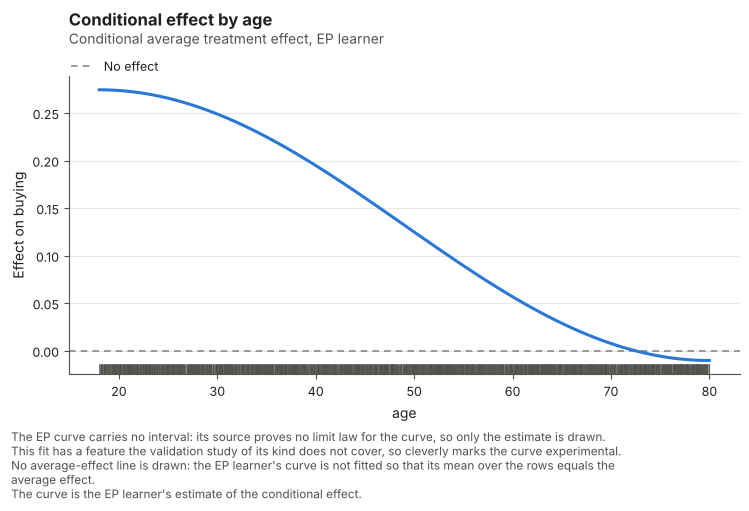

In [5]:
# For your own data, swap in your own learners. Out-of-fold predictions keep a flexible
# learner honest, so a random forest or gradient boosting works here too.
curve = effect.estimate(
    "ep",
    outcome_learner=LogisticRegression(max_iter=1000),
    treatment_learner=LogisticRegression(max_iter=1000),
    random_state=0,
)
# The ages to print; use your own modifier's range.
ages = np.array([20, 30, 40, 50, 60, 70, 80])
print(
    pd.DataFrame(
        {
            "age": ages,
            "estimated effect": curve.predict({"age": ages}),
            "true effect": true_uplift(ages),
        }
    )
    .round(3)
    .to_string(index=False)
)
print()
# curve.sieve is the set of cosine waves on offer; chosen is how many the fit used.
print("cosine waves the curve uses:", curve.sieve.chosen)
print("label:", curve.status)
# The overlap check: the range of the treatment model's predicted chances of a coupon.
chances = curve.diagnostics.support().propensity_quantiles["overall"]
print(f"predicted chance of a coupon: {chances[0.0]:.2f} to {chances[1.0]:.2f}")
curve_fig = curve.plot(modifier="age", outcome_label="buying", treatment_label="a coupon")

The curve falls with age and reaches zero a little after 70, with customers of every age behind it
(the marks along the bottom of the figure). Against the true effect in the table it is a few points
high up to age 60 and slightly low after 70. Its dip below zero at 80 is noise; read it as zero. Cross-validation chose one wave,
the smoothest shape on offer. The outcome model gives the coupon one coefficient shared by every
customer, so it misses the age pattern on its own; the correction recovers it, because the treatment
model matches how coupons were assigned.

`cleverly` labels the fit experimental, because the method's theory does not cover a number of waves
chosen by cross-validation. Simulation studies checked the method with the number of waves set by a
rule in the sample size and one outcome model per treatment arm, and such a fit reads supported. The
curve has no confidence interval either way. You can report it if you say both. For an interval, fit a simple shape such as
a line in age with `cleverly`'s default method, TMLE (targeted maximum likelihood estimation, which
gives intervals for a fixed shape), as the [conditional effects
guide](../user-guide/conditional-effects.md) shows. The interval is then for the straight line
closest to the effect, and a simulation study checked that interval for a fit with one outcome model
per treatment arm.

## Check the curve on held-out rows

The data never show a customer's own effect, because each customer either got a coupon or did
not. The checks use a stand-in: the outcome model's predicted effect for that customer, plus
their weighted prediction error if they got a coupon, or minus it if they did not. One customer's
stand-in is very noisy, but averaged over many customers it is right when either model is right.
Each check splits the rows into folds, refits the whole analysis without one fold, and compares
the curve's predictions on that fold with the stand-ins there.

In [6]:
calibration = curve.diagnostics.calibration()
print("folds:", calibration.n_folds)
print(f"calibration line: intercept {calibration.intercept:.3f}, slope {calibration.slope:.2f}")
bins = calibration.to_frame().rename(
    columns={"mean_prediction": "mean prediction", "pseudo_outcome_contrast": "mean stand-in"}
)
print(bins.round(3).to_string(index=False))
print()
risks = curve.diagnostics.risk_comparison().risks
print("out-of-fold error (lower is better):")
for name in ("curve", "dr_learner", "t_learner", "constant"):
    print(f"  {name:10s} {risks[name]:.4f}")

folds: 5
calibration line: intercept 0.008, slope 0.94
 mean prediction  mean stand-in  rows
           0.006          0.025  1600
           0.045          0.053  1600
           0.119          0.103  1600
           0.211          0.196  1600
           0.275          0.276  1600



out-of-fold error (lower is better):
  curve      -0.0262
  dr_learner -0.0265
  t_learner  -0.0175
  constant   -0.0168


The calibration line regresses the stand-ins on the held-out predictions, and a perfect curve has
intercept 0 and slope 1. Here they are 0.008 and 0.94, and the five groups of 1,600 customers,
sit within 2 points of their stand-ins. At this size the check is too
coarse to see errors of 3 or 4 points: each group's stand-in is uncertain by about 3 points and the
slope by about 0.1. The true effect shows the curve is in fact somewhat too steep, its drop from 20
to 80 about 20% larger than the truth's. On real data, a slope far below 1 means the curve's
differences between ages are too large, and far above 1 too small.

The out-of-fold error scores each candidate against the stand-ins. It leaves out a term shared by
every candidate, so only differences mean anything. The curve scores clearly lower
than one effect for every age (`constant`) and than the outcome model's effect smoothed the same way
(`t_learner`). Regressing the stand-ins on the same functions of age (`dr_learner`) scores about the
same as the curve. These are single numbers with no interval.

## Decide who gets a coupon

Suppose a purchase earns $50 of profit and a coupon costs $4, so a coupon costs the profit of
0.08 purchases. The rule sends a coupon to each customer whose estimated gain in purchase chance
is larger than that.

In [7]:
# Set this from your own numbers: the coupon's cost over the profit of one purchase ($4 / $50).
COST = 0.08
print(f"cost of one coupon, in purchases:  {COST:.2f}")
target = curve.predict({"age": frame["age"]}) > COST
print(f"share of customers targeted:      {target.mean():.3f}")
print(
    f"targeted ages:                    {frame.loc[target, 'age'].min():.0f} to "
    f"{frame.loc[target, 'age'].max():.0f}"
)
# The lines below score the rule with the true effect, which only simulated data have.
gain = true_uplift(frame["age"]) - COST
print(f"true net gain per customer, rule: {np.mean(gain * target):.4f}")
print(f"true net gain, best possible:     {np.mean(gain * (gain > 0)):.4f}")
print(f"true net gain, coupon for all:    {np.mean(gain):.4f}")
grid_ages = np.arange(18, 81)
break_even = grid_ages[true_uplift(grid_ages) > COST].max()
print(f"oldest age whose true gain beats the cost: {break_even}")

cost of one coupon, in purchases:  0.08
share of customers targeted:      0.615
targeted ages:                    18 to 56
true net gain per customer, rule: 0.0529
true net gain, best possible:     0.0543
true net gain, coupon for all:    0.0286
oldest age whose true gain beats the cost: 51


The rule earns almost all of the best possible net gain and much more than a coupon for everyone.
It stops a little late: the true gain beats the cost only up to about age 51, and from 51 to 56
the curve reads about 1.5 to 1.6 times the true effect, so those customers get coupons that lose
a little on average.

Real data have no true effect, so score a rule on customers the curve never saw: fit the curve on
one half and pick the oldest age whose estimated gain beats the cost, which assumes the effect falls
with age. On the other half, `RegimeContrast` estimates how much a `Rule` of coupons up to that age
raises the purchase rate against `Static(0)`, no coupons; a regime is a plan for who gets the coupon
(see [known regimes](../user-guide/estimands.md#known-regimes)). Subtracting the cost of the rule's
coupons gives the net gain, with an interval.

cosine waves on the first half:    1
cutoff chosen on the first half:   age 54
rise in purchases, rule vs none:   0.117 (95% interval 0.092 to 0.141)
cost of its coupons per customer:  0.046
net gain per customer:             0.071 (95% interval 0.046 to 0.096)
true net gain on this half:        0.053
status: experimental



gain, top 40% treated:    0.102 (a random 40%: 0.056)
area summary (AUTOC):     0.089 (95% interval 0.056 to 0.122)
status: supported


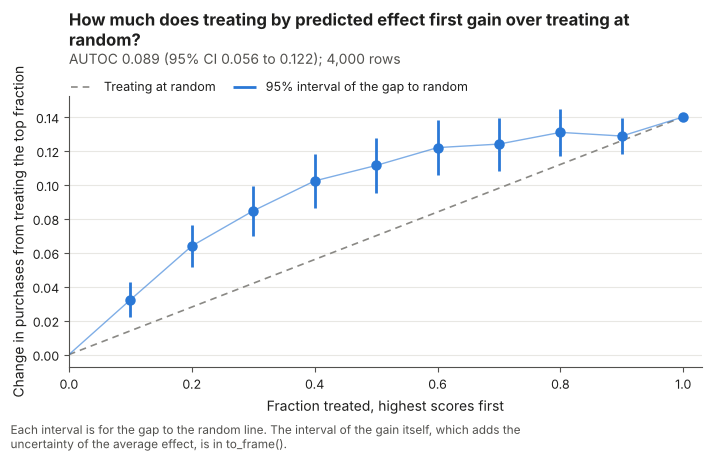

In [8]:
# On real data, score the rule on rows the curve never saw: fit the curve and choose the
# cutoff age on one half, then estimate on the other half how much the rule raises the
# purchase rate against sending no coupons.  rule_kind="known" says the rule is fixed
# before this fit, which the split makes true.
from cleverly import RegimeContrast
from cleverly.interventions import Rule, Static

learners = {
    "outcome_learner": LogisticRegression(max_iter=1000),
    "treatment_learner": LogisticRegression(max_iter=1000),
}
half = frame.sample(frac=0.5, random_state=0).index
first, second = frame.loc[half], frame.drop(index=half)
first_curve = (
    CausalStudy(first, design=study.design)
    .identify(ConditionalContrast(by_age))
    .estimate("ep", **learners, random_state=0)
)
# The ages to search, your modifier's range; the oldest age above the cost is the cutoff.
grid = np.arange(18, 81)
cutoff = int(grid[first_curve.predict({"age": grid}) > COST].max())
rule = Rule(lambda rows: (rows["age"] <= cutoff).astype(float), name="rule", rule_kind="known")
scored = CausalStudy(second, design=study.design).estimate(
    RegimeContrast((rule, Static(0, name="no coupon")), reference="no coupon"),
    **learners,
    random_state=0,
)
# psi is the estimate; support is its status (validated or experimental).
rise = scored.to_frame().iloc[0]
coupon_cost = COST * (second["age"] <= cutoff).mean()
print("cosine waves on the first half:   ", first_curve.sieve.chosen)
print(f"cutoff chosen on the first half:   age {cutoff}")
print(
    f"rise in purchases, rule vs none:   {rise['psi']:.3f} "
    f"(95% interval {rise['ci_lower']:.3f} to {rise['ci_upper']:.3f})"
)
print(f"cost of its coupons per customer:  {coupon_cost:.3f}")
print(
    f"net gain per customer:             {rise['psi'] - coupon_cost:.3f} "
    f"(95% interval {rise['ci_lower'] - coupon_cost:.3f} to "
    f"{rise['ci_upper'] - coupon_cost:.3f})"
)
# The truth, which only simulated data have:
true_net = np.mean((true_uplift(second["age"]) - COST) * (second["age"] <= cutoff))
print(f"true net gain on this half:        {true_net:.3f}")
print("status:", rise["support"])

# Rank the held-out customers by the first half's curve, then estimate on them how much the
# treated top share gains. Treating at random is the straight line to the gain of treating everyone.
held_out = second.assign(priority=first_curve.predict({"age": second["age"]}))
ranking = (
    CausalStudy(held_out, design=study.design)
    .identify(ConditionalContrast(by_age))
    .targeting_curve(
        "priority", computed_from=["age"], score_kind="external", **learners, random_state=0
    )
)
# Budgets are shares of customers treated; use any grid in (0, 1].
at_40 = {row["q"]: row for row in ranking.rows("gain")}[0.4]
autoc = ranking.area("autoc")
print()
print(f"gain, top 40% treated:    {at_40['estimate']:.3f} (a random 40%: {0.4 * ranking.ate:.3f})")
print(
    f"area summary (AUTOC):     {autoc['estimate']:.3f} "
    f"(95% interval {autoc['lower']:.3f} to {autoc['upper']:.3f})"
)
print("status:", ranking.status)
ranking_fig = ranking.plot(
    view="gain", outcome_label="purchases", labels={"priority": "predicted effect"}
)

On half the customers, cross-validation again chose one wave, and the cutoff came out at 54, close
to the 56 from all customers. Scored on the other half, that rule is estimated to earn 0.071 net
purchases per customer, with a 95% interval of 0.046 to 0.096; the true value on that half, 0.053, lies
inside. This estimate is labelled experimental too, because no validation study covers this kind of
rule fit, so its interval has not been checked by simulation.

Ranking those customers by the first half's curve, treating the top 40% gains 0.102 purchases per
customer in all, against 0.056 for a random 40%. The area summary (AUTOC) averages, over budgets,
how much more the top group gains than the average customer: 0.089, with the interval above. These
numbers can be trusted only because the ranking never saw these customers' outcomes. The bars in the
figure are 95% intervals for the gap to random targeting, one budget at a time, not one joint band.

## What we can and can't conclude

For the marketing team: the coupon's effect falls with age, and coupons for customers up to about 56
earn almost the best gain possible in this simulation and nearly twice the gain of a coupon for
everyone. Scored on held-out customers, a rule learned from half of them is estimated, with a 95%
interval, to earn between 0.046 and 0.096 net purchases per customer. That rests above all on age,
spend and visits accounting for how the team chose who got a coupon, which no held-out score can
check. So before rolling the rule out, send coupons by the rule to a random share of customers and
keep another random share on current practice: that holdout tests the rule without relying on those
conditions.

The page does not show that the estimated curve is the true curve for your data, that a rule
learned on one sample earns the same on the next, or anything about how the method performs in
general.

## Go deeper

### A trial: does the drug help sicker patients more?

A randomized drug trial shows the method on a ratio, with a treatment model known to be right
because the drug was assigned at random. In a simulated trial of 2,000 patients, the question is
how the risk ratio (the risk of an event with the drug divided by the risk without it) changes
with a severity score from 0 to 1.

`Cosine(["severity"], 6)` offers up to six cosine waves in severity, and `Sieve(..., size=1)`
fixes the curve to the first of them before the fit, as a trial's analysis plan would. The fit is
still labelled experimental and still has no interval. Adjusting for severity and age is not
needed against confounding in a trial, but it can make the estimate more precise. On this scale
`predict` returns the log of the risk ratio, so the code applies `np.exp`.

In [9]:
from cleverly.bases import Cosine, Sieve


def simulate_trial(n, seed):
    rng = np.random.default_rng(seed)
    severity = rng.uniform(0, 1, n)  # a baseline severity score, 0-1
    age = rng.uniform(40, 80, n)
    drug = rng.binomial(1, 0.5, n)  # assigned at random
    risk = 0.20 + 0.40 * severity + 0.002 * (age - 60)
    event = rng.binomial(1, risk * np.exp(drug * (-0.8 * severity)))
    return pd.DataFrame({"severity": severity, "age": age, "drug": drug, "event": event})


trial = simulate_trial(n=2_000, seed=1)
trial_effect = CausalStudy(
    trial,
    design=PointTreatment(outcome="event", treatment="drug", adjustment=("severity", "age")),
).identify(
    ConditionalContrast(Modifiers(["severity"], domains={"severity": (0, 1)}), scale="log_ratio")
)
ratio_curve = trial_effect.estimate(
    "ep",
    outcome_learner=LogisticRegression(max_iter=1000),
    treatment_learner=LogisticRegression(max_iter=1000),
    sieve=Sieve(Cosine(["severity"], 6), size=1),
    random_state=0,
)
levels = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
print(
    pd.DataFrame(
        {
            "severity": levels,
            "estimated risk ratio": np.exp(ratio_curve.predict({"severity": levels})),
            "true risk ratio": np.exp(-0.8 * levels),
        }
    )
    .round(2)
    .to_string(index=False)
)

 severity  estimated risk ratio  true risk ratio
     0.00                  1.03             1.00
     0.25                  0.92             0.82
     0.50                  0.70             0.67
     0.75                  0.54             0.55
     1.00                  0.48             0.45


In this simulation, yes: the drug cuts the risk more for sicker patients, from almost no change at
the lowest severity to about half the risk at the highest, close to the true ratios except near
severity 0.25 (0.92 against 0.82).

### What has been checked so far

The package's tests check the correction exactly on small made-up populations whose answer is
known, including when the outcome model is wrong. Two simulation studies compared the curve with a
reference fit that knew the true models, and a third checked the curve's diagnostics; all three
passed. A comparison with the R package hte3 is planned and has not run. The
[conditional effects guide](../user-guide/conditional-effects.md) summarizes the studies, and the
[conditional effects reference](../technical-reference/conditional-effects.md) states what they
measure and what the theory claims.

### Does the coupon curve depend on how the rows were split?

Back to the coupon curve: its out-of-fold fits split the rows at random. `stability()` refits the
curve under five different splits of the same rows and compares the spread of those refits with the
spread of the curve across ages.

In [10]:
stability = curve.diagnostics.stability()
print(f"spread across 5 refits, relative to the curve's own spread: {stability.relative_sd:.3f}")
print("warning:", stability.warning)

spread across 5 refits, relative to the curve's own spread: 0.074


The refits move by less than a tenth (0.074) of the curve's own spread, well below the level at
which `cleverly` warns (a half). This measures sensitivity to the split on the same data, not
sampling noise. A value above a half would mean the curve depends on how the rows happen to be
split, and a simpler shape or more data would be the next step. A low value, as here, rules that
out but does not show that the curve is well determined.

## Where to go next

The [conditional effects guide](../user-guide/conditional-effects.md) covers the simple shapes
with intervals. The [one treatment, one outcome](point-treatment-tmle.ipynb)
example explains the outcome and treatment models step by step, and
[who should get the offer](treatment-rules.ipynb) learns a treatment rule directly. The
[examples index](index.md) lists every example.